# How many teacher labels does a potential actually need?

This tutorial runs the whole active-learning pipeline of this repository at
miniature scale, offline, in a few minutes on CPU: generate candidate
structures, hide their labels behind a purchase counter, train a small deep
ensemble, buy labels where the committee disagrees, and compare against
random selection at the same budget.

Two things to keep straight throughout:

- **Labels are surrogate model labels.** They come from CHGNet, a pretrained
  universal potential, not from DFT. The committed sample used here carries
  those teacher labels so the notebook needs no teacher install.
- **This is the miniature.** The committed benchmark (results/metrics.json)
  uses the full pool, five members, and three seeds; the last cell compares
  this miniature against it.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from falearn import (
    AcsfParams,
    EvalSet,
    LabeledPool,
    LoopSettings,
    TrainSettings,
    frame_graph,
    load_frames,
    pool_test_split,
    run_loop,
)
from falearn.calibration import binned_reliability
from falearn.data import group_kind
from falearn.structures import build_dataset

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
C_ACTIVE, C_RANDOM, C_MUTED = "#2a78d6", "#eb6834", "#898781"

## 1. Candidate generation

Candidates are BCC Ti-Zr-Nb supercells with random site occupancy, rattled
at several amplitudes or strained, grouped by generation batch. Generation
is teacher-free: nothing about the labels shapes the pool. Here is what one
batch looks like, and how amplitude spreads the interatomic distances.

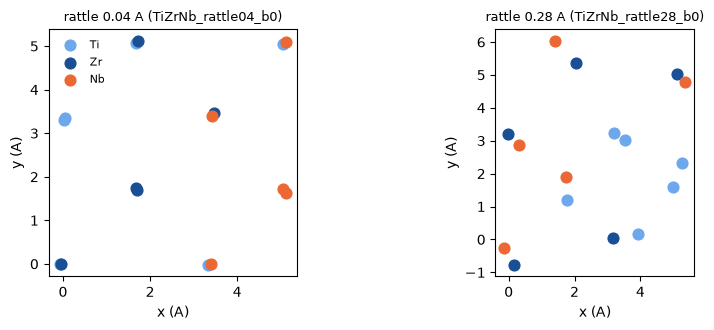

In [2]:
demo = build_dataset(("TiZrNb",), rattle_amplitudes=(0.04, 0.28), batches_per_kind=1,
                     frames_per_batch=4, seed=7)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
colors = {0: "#6da7ec", 1: "#184f95", 2: "#eb6834"}
soft, hard = demo[0], demo[4]
for ax, fr, title in ((axes[0], soft, "rattle 0.04 A"), (axes[1], hard, "rattle 0.28 A")):
    for t, name in ((0, "Ti"), (1, "Zr"), (2, "Nb")):
        sel = fr.species == t
        ax.scatter(fr.positions[sel, 0], fr.positions[sel, 1], s=60, c=colors[t], label=name)
    ax.set_title(f"{title} ({fr.group})", fontsize=9)
    ax.set_xlabel("x (A)"); ax.set_ylabel("y (A)"); ax.set_aspect("equal")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 2. The committed sample and the leakage-safe split

The committed sample is a carve of whole generation groups from the full
teacher-labeled dataset. The split keeps whole groups and whole
compositions together: sibling frames from one rattle batch can never sit
on both sides, and two compositions (Ti2ZrNb, TiZrNb2) never enter the pool
at all.

278 frames, 30 generation groups
pool 166, held-out-group test 56, held-out-composition transfer 56


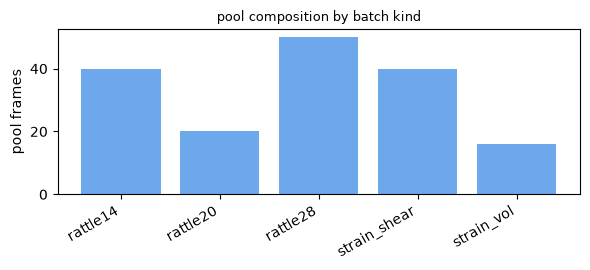

In [3]:
frames = load_frames(REPO / "data" / "sample_frames.extxyz")
split = pool_test_split(frames, holdout_compositions=("Ti2ZrNb", "TiZrNb2"),
                        test_fraction=0.2, seed=20260809)
print(f"{len(frames)} frames, {len({f.group for f in frames})} generation groups")
print(f"pool {len(split.pool)}, held-out-group test {len(split.test)}, "
      f"held-out-composition transfer {len(split.transfer)}")
kinds = {}
for k in split.pool:
    kd = group_kind(frames[k].group, frames[k].composition)
    kinds[kd] = kinds.get(kd, 0) + 1
fig, ax = plt.subplots(figsize=(6, 2.8))
names = sorted(kinds)
ax.bar(names, [kinds[n] for n in names], color="#6da7ec")
ax.set_ylabel("pool frames"); ax.set_title("pool composition by batch kind", fontsize=9)
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

## 3. Hide the labels, run both strategies

`LabeledPool` moves every label into a private store; selection code sees
structures only, and labels become readable exactly when purchased. The
committee strategy ranks candidates by force disagreement (RMS deviation of
member forces from the committee mean); the baseline buys uniformly at
random. Both share the identical initial draw and training settings.

This miniature uses 3 members, a 60-label budget, and the same
equal-effort epoch rule as the committed benchmark (scaled down); the
committed benchmark uses 5 members, 300 labels, and 3 seeds.

In [4]:
acsf = AcsfParams()
test_frames = [frames[k] for k in split.test]
test_set = EvalSet(
    name="test",
    graphs=[frame_graph(fr, acsf) for fr in test_frames],
    energies=np.array([fr.energy for fr in test_frames]),
    forces=[fr.forces for fr in test_frames],
)
histories = {}
for strategy in ("committee", "random"):
    pool = LabeledPool([frames[k] for k in split.pool])
    settings = LoopSettings(
        strategy=strategy, n_members=3, hidden=(8,), n_init=24, round_size=12,
        n_rounds=3, seed=0,
        train=TrainSettings(epochs=25, batch_size=12, target_frame_epochs=4000, max_epochs=100),
    )
    histories[strategy], members = run_loop(pool, [test_set], settings, acsf=acsf)
    final = histories[strategy]["rounds"][-1]["metrics"]["test"]
    print(f"{strategy:<10} final budget {histories[strategy]['rounds'][-1]['budget']}: "
          f"E MAE {final['e_mae_mev_per_atom']:.1f} meV/atom, "
          f"F MAE {final['f_mae_mev_per_a']:.1f} meV/A")

committee  final budget 60: E MAE 52.3 meV/atom, F MAE 253.3 meV/A


random     final budget 60: E MAE 45.9 meV/atom, F MAE 230.6 meV/A


## 4. Error versus labels

The benchmark question in one picture: at every budget along the schedule,
which strategy has the lower held-out error?

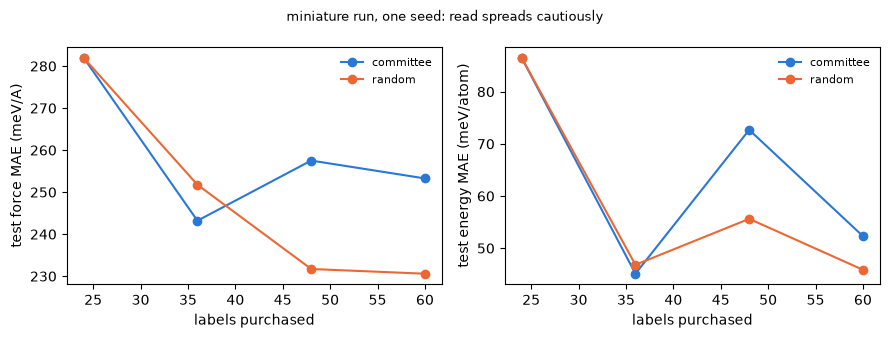

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for strategy, color in (("committee", C_ACTIVE), ("random", C_RANDOM)):
    rounds = histories[strategy]["rounds"]
    budgets = [r["budget"] for r in rounds]
    axes[0].plot(budgets, [r["metrics"]["test"]["f_mae_mev_per_a"] for r in rounds],
                 color=color, marker="o", label=strategy)
    axes[1].plot(budgets, [r["metrics"]["test"]["e_mae_mev_per_atom"] for r in rounds],
                 color=color, marker="o", label=strategy)
axes[0].set_ylabel("test force MAE (meV/A)")
axes[1].set_ylabel("test energy MAE (meV/atom)")
for ax in axes:
    ax.set_xlabel("labels purchased"); ax.legend(frameon=False, fontsize=8)
fig.suptitle("miniature run, one seed: read spreads cautiously", fontsize=9)
plt.tight_layout(); plt.show()

## 5. Is the uncertainty honest?

Acquisition only works if committee disagreement actually tracks error.
On the held-out test frames we can check: each point is one frame,
disagreement against the true force RMSE of the committee mean.

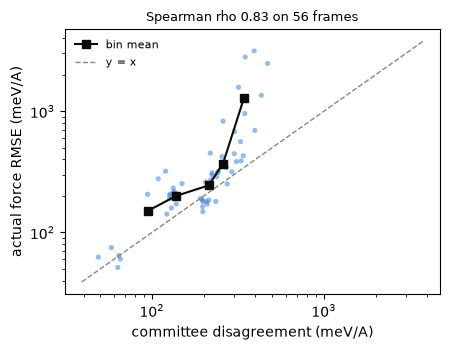

In [6]:
cal = histories["committee"]["calibration"]
d = np.array(cal["disagreement_mean_mev_per_a"])
e = np.array(cal["f_rmse_mev_per_a"])
rel = binned_reliability(d, e, n_bins=5)
fig, ax = plt.subplots(figsize=(4.6, 3.6))
ax.scatter(d, e, s=14, color=C_ACTIVE, alpha=0.5, edgecolors="none")
ax.plot(rel["bin_median_disagreement"], rel["bin_mean_error"], color="#0b0b0b",
        marker="s", label="bin mean")
lim = [min(d.min(), e.min()) * 0.8, max(d.max(), e.max()) * 1.2]
ax.plot(lim, lim, ls="--", color=C_MUTED, lw=1, label="y = x")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("committee disagreement (meV/A)")
ax.set_ylabel("actual force RMSE (meV/A)")
ax.set_title(f"Spearman rho {rel['spearman_rho']:.2f} on {rel['n_frames']} frames", fontsize=9)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 6. What did the committee buy?

The acquisition record shows where the budget went: batch kinds of the
purchased frames per round, against the pool's own mix.

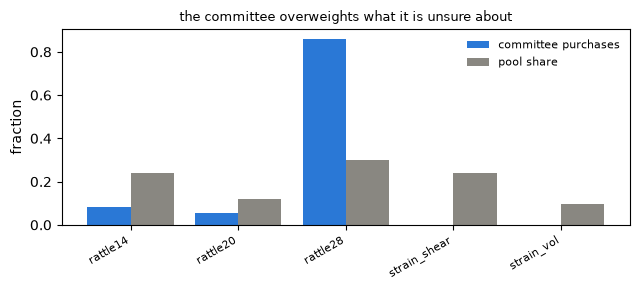

In [7]:
rounds = histories["committee"]["rounds"]
pool_kinds = {}
for k in split.pool:
    kd = group_kind(frames[k].group, frames[k].composition)
    pool_kinds[kd] = pool_kinds.get(kd, 0) + 1
names = sorted(pool_kinds)
pool_frac = np.array([pool_kinds[n] for n in names], dtype=float)
pool_frac /= pool_frac.sum()
bought = {n: 0 for n in names}
for r in rounds:
    for s in r.get("selected", []):
        if s["kind"] in bought:
            bought[s["kind"]] += 1
total = max(1, sum(bought.values()))
fig, ax = plt.subplots(figsize=(6.5, 3))
x = np.arange(len(names))
ax.bar(x - 0.2, [bought[n] / total for n in names], width=0.4, color=C_ACTIVE,
       label="committee purchases")
ax.bar(x + 0.2, pool_frac, width=0.4, color=C_MUTED, label="pool share")
ax.set_xticks(x); ax.set_xticklabels(names, rotation=30, ha="right", fontsize=8)
ax.set_ylabel("fraction"); ax.legend(frameon=False, fontsize=8)
ax.set_title("the committee overweights what it is unsure about", fontsize=9)
plt.tight_layout(); plt.show()

## 7. The miniature against the committed benchmark

The committed numbers come from the full run (five members, 300-label
budget, three seeds, full pool); this cell reads them from
results/metrics.json rather than repeating them by hand.

In [8]:
import json

metrics = json.loads((REPO / "results" / "metrics.json").read_text())
curves = metrics["curves"]["f_mae_mev_per_a"]
e_curves = metrics["curves"]["e_mae_mev_per_atom"]
red = metrics["label_reduction"]["committee"]["force"]
print("full benchmark, final budget "
      f"{curves['committee']['budgets'][-1]} labels (mean over 3 seeds):")
for s, name in (("committee", "committee"), ("committee_capped", "committee+cap"),
                ("random", "random")):
    if s in curves:
        print(f"  {name:<14} F MAE {curves[s]['mean'][-1]:6.1f} +/- {curves[s]['std'][-1]:.1f} "
              f"meV/A   E MAE {e_curves[s]['mean'][-1]:5.1f} meV/atom")
if red["reached"]:
    print(f"  committee reaches random's final error at ~{red['active_budget_at_target']:.0f} "
          f"labels: {red['reduction_factor']:.2f}x fewer labels")
else:
    print("  committee does NOT reach random's final error within the budget: on this")
    print("  mixed pool, random selection wins at matched budget (see RESULTS.md)")
rhos = [c["spearman_rho"] for c in metrics["calibration"]]
print(f"  calibration Spearman rho across committee runs: "
      f"{', '.join(f'{r:.2f}' for r in rhos)}")
if "scarce" in metrics:
    sc = metrics["scarce"]["curves"]["f_mae_mev_per_a"]
    print(f"  scarce pool ({metrics['scarce']['n_pool']} frames, informative frames rare): "
          f"committee F {sc['committee']['mean'][-1]:.1f} vs random {sc['random']['mean'][-1]:.1f}")
mini = histories["committee"]["rounds"][-1]["metrics"]["test"]
print(f"\nminiature (this notebook): committee F MAE {mini['f_mae_mev_per_a']:.1f} meV/A "
      f"at budget {histories['committee']['rounds'][-1]['budget']}")
print("the miniature is one seed at a small budget; quote the committed numbers, not these")

full benchmark, final budget 300 labels (mean over 3 seeds):
  committee      F MAE  185.6 +/- 5.9 meV/A   E MAE  28.1 meV/atom
  committee+cap  F MAE  183.5 +/- 0.7 meV/A   E MAE  28.4 meV/atom
  random         F MAE  175.1 +/- 6.0 meV/A   E MAE  18.1 meV/atom
  committee does NOT reach random's final error within the budget: on this
  mixed pool, random selection wins at matched budget (see RESULTS.md)
  calibration Spearman rho across committee runs: 0.87, 0.88, 0.91, 0.90, 0.88, 0.91
  scarce pool (480 frames, informative frames rare): committee F 202.7 vs random 208.4

miniature (this notebook): committee F MAE 253.3 meV/A at budget 60
the miniature is one seed at a small budget; quote the committed numbers, not these


## Takeaways

- The loop's plumbing is what makes the claim checkable: hidden labels with
  an explicit purchase step, whole-group splits, and one shared initial
  draw per seed.
- Read error-versus-labels curves with their spread; single-seed miniatures
  like this one wobble.
- Calibration is measured, not assumed, and the full benchmark reports it
  per seed alongside any regime where random ties or wins.